# Preparar los datos del Titanic

# Capítulo 3 · Proyecto Titanic



In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)

## 1. Primer Contacto

- [ ] Primeras/Ultimas filas, shape y tipos de dato
- [ ] Resumen estadístico de numéricas y de categóricas.
- [ ] Faltantes por columna (número y %), filas duplicadas y valores únicos de cada categóric

In [2]:
import pandas as pd
df = pd.read_csv("/home/joseph/Proyectos/SamsungInnovation-1-/data/titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [4]:
df.shape

(891, 15)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [6]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.describe(exclude="number")

,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


In [8]:
df["who"].value_counts()

who
man      537
woman    271
child     83
Name: count, dtype: int64

In [9]:
for col in ["sex", "embarked", "class", "who", "deck", "embark_town", "alive"]:
    print(df[col].value_counts(dropna=False), "\n")

sex
male      577
female    314
Name: count, dtype: int64 

embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64 

class
Third     491
First     216
Second    184
Name: count, dtype: int64 

who
man      537
woman    271
child     83
Name: count, dtype: int64 

deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64 

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64 

alive
no     549
yes    342
Name: count, dtype: int64 



¿Clasificación o regresión? · ¿Qué numérica se comporta como categórica, y qué categórica tiene orden? · ¿Qué
parejas de columnas dicen lo mismo? Compruébalo. · ¿Qué pasa si le das alive al modelo?

**📋 Resultado del diagnóstico**

| Problema | Dónde | Se arregla en |
|---|---|---|
| Filas duplicadas | 107 filas | 1.1 |
| Texto inconsistente | `barrio` ("Centro", "CENTRO", "  centro ") | 1.2 |
| Tipos incorrectos | `survived` ,(texto con `$` y comas), `fecha_venta` | 1.3 |
| Valores faltantes | `age`,`embarked`,`deck`,`embarked` | 1.4 |
| Valores extremos | `precio`, `distancia_metro_m` | 1.5 |

## 2. Analisis Exploratorio

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

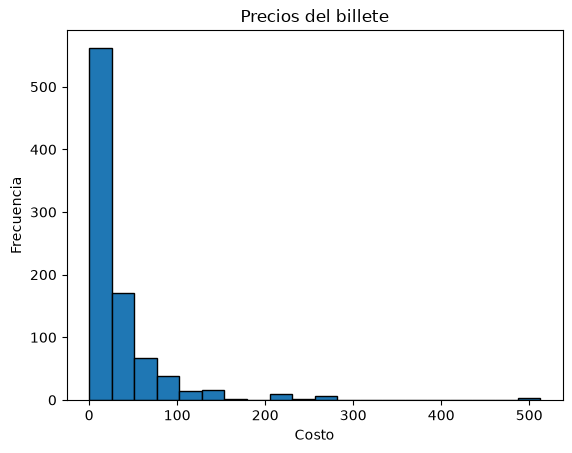

In [11]:
fig, ax= plt.subplots()
ax.hist(df["fare"],
        bins=20,
        edgecolor="black")
ax.set_xlabel("Costo")
ax.set_ylabel("Frecuencia")
ax.set_title("Precios del billete")
plt.show()


Por la distribucion que tienen los valores, o se trata de salas delujo, demasiado alejadas a una primera clase, o se trata de una variacion de un outlier

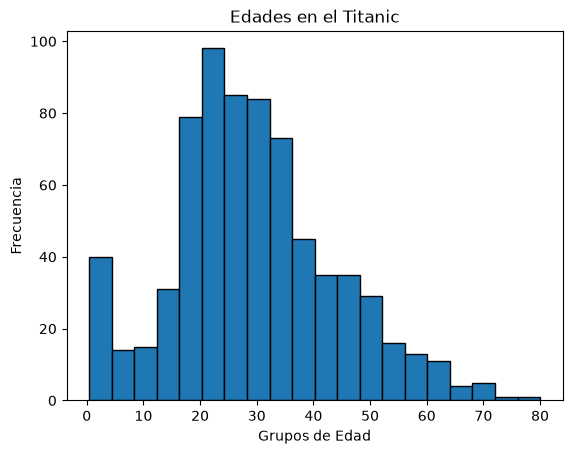

In [12]:
fig, ax= plt.subplots()
ax.hist(df["age"],
        bins=20,
        edgecolor="black")
ax.set_xlabel("Grupos de Edad")
ax.set_ylabel("Frecuencia")
ax.set_title("Edades en el Titanic")
plt.show()

Aqui lo bueno es que se ve una cierta curva en la informacion, lo cual muestra que la informacion no esta tan dispersa como se pensaria

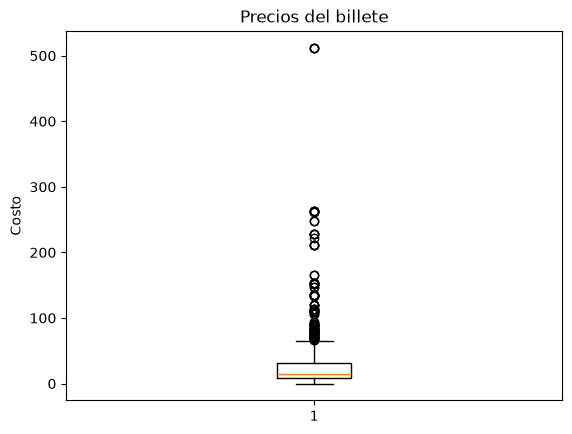

In [13]:
fig, ax= plt.subplots()
ax.boxplot(df["fare"])
ax.set_ylabel("Costo")
ax.set_title("Precios del billete")
plt.show()


Aqui como se menciono previamente, hay varios costos que actuan como outliers, debido a la cantidad de acumulacion que existe posterior al 3er cuartile, muestra que son bastantes los que estan fuera de lo comun, lo interesante seria saber si corresponden a clases mas altas del titanic

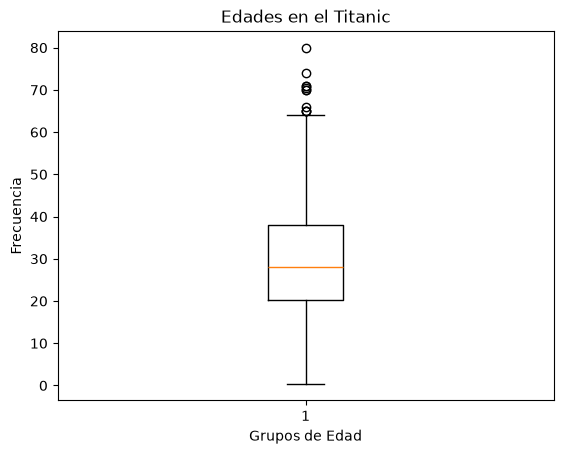

In [14]:
fig, ax= plt.subplots()
ax.boxplot(df["age"].dropna())
ax.set_xlabel("Grupos de Edad")
ax.set_ylabel("Frecuencia")
ax.set_title("Edades en el Titanic")
plt.show()

Las edades, se ven con variaciones mas razonables, sobre todo porque se trata de edades de 80 años, entonces no es descabellado verlos como casos especiales mas que como outliers, AUNQUE es importante mencionar que para realizarlo se necesito de usar un dropna, debido a valores faltantes, lo cual puede mostrar que podria hbaer una variacion muy grande de datos

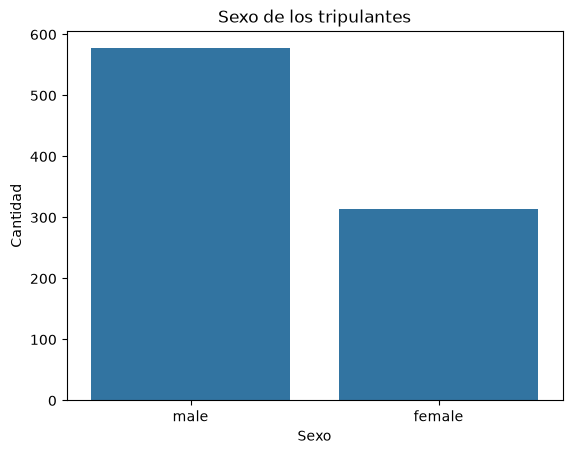

In [15]:
fig,ax = plt.subplots()
sns.countplot(df,x="sex",ax=ax)
ax.set_title("Sexo de los tripulantes")
ax.set_xlabel("Sexo")
ax.set_ylabel("Cantidad")
plt.show()

Este grafico muestra que son principalmente usuarios masculinos los tripulantes del titanic

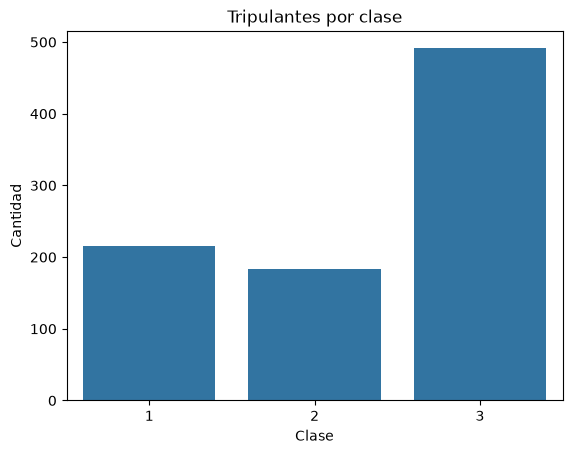

In [16]:
fig,ax = plt.subplots()
sns.countplot(df,x="pclass",ax=ax)
ax.set_title("Tripulantes por clase")
ax.set_xlabel("Clase")
ax.set_ylabel("Cantidad")
plt.show()


Aqui podemos ver que la mayoria de los tripulantes, son de 3era clase, seguidos por primera clase, lo cual muestra una tripulacion con mayor poder adquisitivo

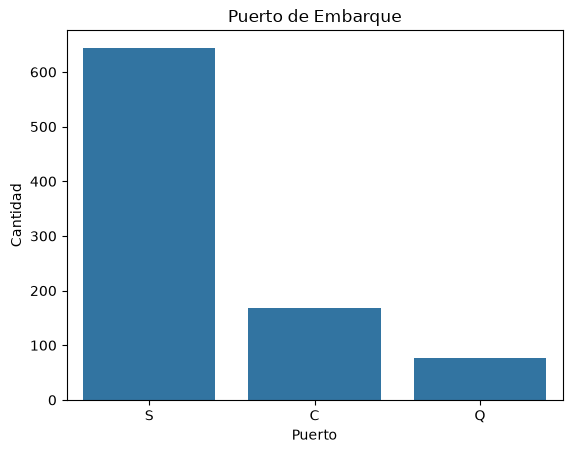

In [17]:
fig,ax = plt.subplots()
sns.countplot(df,x="embarked",ax=ax)
ax.set_title("Puerto de Embarque")
ax.set_xlabel("Puerto")
ax.set_ylabel("Cantidad")
plt.show()

Aqui podemos observar que la mayoria de los que tomaron el titanic, tomaron el puerto de Southampton, siendo casi toda la tripulacion, lo cual con respecto a los anteriores graficos, podria implicar que la ciudad de Southampton es una zona donde coexisten diversos entornos socioeconomicos 

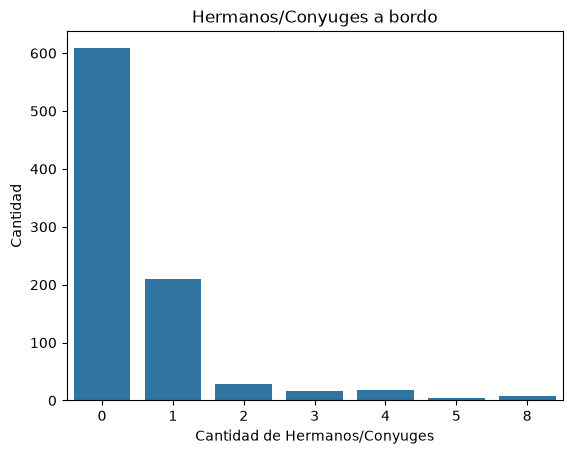

In [18]:
fig,ax = plt.subplots()
sns.countplot(df,x="sibsp",ax=ax)
ax.set_title("Hermanos/Conyuges a bordo")
ax.set_xlabel("Cantidad de Hermanos/Conyuges")
ax.set_ylabel("Cantidad")
plt.show()

Aqui, esto muestra que la mayoria de la tripulacion es soltera o se encuentra con poca familia, seguidos por familias que iban solo acompañados por un hermano o conyugue, otro dato importante es que segun la contabilizacion, existe una pequeña cantidad de tripulantes que iban en una familia de 8

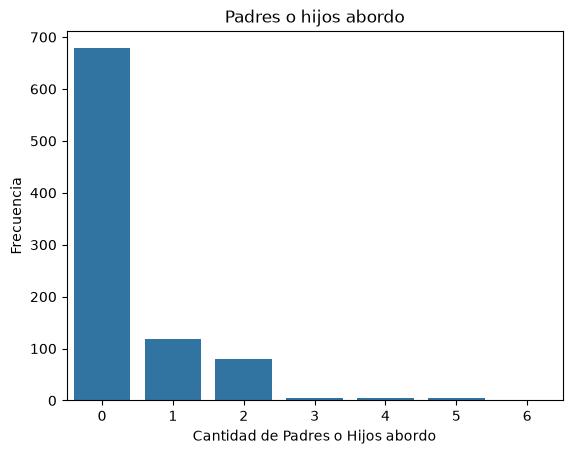

In [19]:
fig,ax = plt.subplots()
sns.countplot(df,x="parch",ax=ax)
ax.set_title("Padres o hijos abordo")
ax.set_xlabel("Cantidad de Padres o Hijos abordo")
ax.set_ylabel("Frecuencia")
plt.show()


Siguiendo lo mencionado previamente, son la mayoria de los tripulantes, los que viajaban solos, por lo que corrobora que eran pocos los que pertenecian a familias

## 3. Limpieza datos

### [x] Copia: guarda los datos originales antes de tocar nada.

In [20]:
titanic=df.copy()

### [X] Redundancia y fuga: elimina columnas repetidas. ¿Qué haces con who y adult_male? *¿Qué columna provoca data leakage?*

Considero que es mejor manejar embarked por puertos en texto, ya que permitiria indentificar una zona geografica, y alive, considero quitarla, ya que es mas facil manejarla como binaria
y que class es mejor con pclass

In [21]:
titanic=titanic.drop(columns=["embarked","alive","class","adult_male"])
#titanic=titanic.drop(columns=["embarked","alive","class"])
titanic.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'who',
       'deck', 'embark_town', 'alone'],
      dtype='str')

**¿Que se hace con who y adult_male?**

Creo que deberian conservarse, ya que facilitan la categorizacion, la primera para poseteriormente llenar valores faltantes y la segunda, para distinguir adultos de menores

**¿Que columna produce data leakage?**

survived y alive 

### [ ] Duplicados: no hay nombre ni billete. ¿Son errores o personas distintas?

In [22]:
#titanic[titanic.duplicated()].sort_values(by=list(titanic.columns))
titanic.duplicated().sum()

np.int64(107)

### [ ] Faltantes: decide para deck, age y embarked. ¿Eliminar, media, mediana por grupo, moda o indicador?

- Deck: Mediana por grupo (por medio de `fare`)
- Age: Mediana por grupo (por medio de `who`)
- Embarked: Moda (`embark_town`)

In [23]:
ORDEN_DECK = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6}

titanic["deck_faltante"] = titanic["deck"].isna()           # antes de rellenar
titanic["deck"] = titanic["deck"].astype(object).map(ORDEN_DECK)

titanic["deck"] = titanic["deck"].fillna(
    titanic.groupby("pclass")["deck"].transform("median").round()
)

In [24]:
titanic["edad_faltante"] = titanic["age"].isna()     # antes de rellenar
titanic["age"] = titanic["age"].fillna(
    titanic.groupby("who")["age"].transform("median")
)

In [25]:
moda = titanic["embark_town"].mode()[0]    # mode() devuelve una Series: nos quedamos con el primer valor
print("Moda:", moda)

titanic["embark_town"] = titanic["embark_town"].fillna(moda)
titanic["embark_town"].value_counts()

Moda: Southampton


embark_town
Southampton    646
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

### [ ] Outliers: revisa fare, age, sibsp y parch con IQR y Z-score. ¿Error o valor raro pero real?


In [26]:
cols_out = ["fare", "age", "sibsp", "parch"]
datos = titanic[cols_out]

# Z-score
z = (datos - datos.mean()) / datos.std()
outliers_z = (z.abs() > 3).sum()

# IQR
q1 = datos.quantile(0.25)
q3 = datos.quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
outliers_iqr = ((datos < limite_inf) | (datos > limite_sup)).sum()

pd.DataFrame({
    "outliers z-score": outliers_z,
    "outliers IQR": outliers_iqr,
    "límite inf. IQR": limite_inf,
    "límite sup. IQR": limite_sup,
})

,outliers z-score,outliers IQR,límite inf. IQR,límite sup. IQR
fare,20,116,-26.724,65.6344
age,7,66,2.500,54.5000
sibsp,30,46,-1.500,2.5000
parch,15,213,0.000,0.0000


### [ ] Antes vs. después: compara filas, faltantes, distribuciones y % de supervivientes.

In [27]:
casos = {
    "fare == 0": titanic["fare"] == 0,
    "fare > 500": titanic["fare"] > 500,
    "age < 1": titanic["age"] < 1,
    "sibsp == 8": titanic["sibsp"] == 8,
}

resumen_casos = pd.DataFrame({
    nombre: {
        "filas": mascara.sum(),
        "% supervivientes": round(titanic.loc[mascara, "survived"].mean() * 100, 1),
    }
    for nombre, mascara in casos.items()
}).T
display(resumen_casos)

for nombre, mascara in casos.items():
    print(f"\n--- {nombre} ---")
    display(titanic[mascara])

,filas,% supervivientes
fare == 0,15.0,6.7
fare > 500,3.0,100.0
age < 1,7.0,100.0
sibsp == 8,7.0,0.0



--- fare == 0 ---


,survived,pclass,sex,age,sibsp,parch,fare,who,deck,embark_town,alone,deck_faltante,edad_faltante
179,0,3,male,36.0,0,0,0.0,man,5.0,Southampton,True,True,False
263,0,1,male,40.0,0,0,0.0,man,1.0,Southampton,True,False,False
271,1,3,male,25.0,0,0,0.0,man,5.0,Southampton,True,True,False
277,0,2,male,30.0,0,0,0.0,man,4.0,Southampton,True,True,True
302,0,3,male,19.0,0,0,0.0,man,5.0,Southampton,True,True,False
413,0,2,male,30.0,0,0,0.0,man,4.0,Southampton,True,True,True
466,0,2,male,30.0,0,0,0.0,man,4.0,Southampton,True,True,True
481,0,2,male,30.0,0,0,0.0,man,4.0,Southampton,True,True,True
597,0,3,male,49.0,0,0,0.0,man,5.0,Southampton,True,True,False
633,0,1,male,30.0,0,0,0.0,man,2.0,Southampton,True,True,True



--- fare > 500 ---


,survived,pclass,sex,age,sibsp,parch,fare,who,deck,embark_town,alone,deck_faltante,edad_faltante
258,1,1,female,35.0,0,0,512.3292,woman,2.0,Cherbourg,True,True,False
679,1,1,male,36.0,0,1,512.3292,man,1.0,Cherbourg,False,False,False
737,1,1,male,35.0,0,0,512.3292,man,1.0,Cherbourg,True,False,False



--- age < 1 ---


,survived,pclass,sex,age,sibsp,parch,fare,who,deck,embark_town,alone,deck_faltante,edad_faltante
78,1,2,male,0.83,0,2,29.0000,child,4.0,Southampton,False,True,False
305,1,1,male,0.92,1,2,151.5500,child,2.0,Southampton,False,False,False
469,1,3,female,0.75,2,1,19.2583,child,5.0,Cherbourg,False,True,False
644,1,3,female,0.75,2,1,19.2583,child,5.0,Cherbourg,False,True,False
755,1,2,male,0.67,1,1,14.5000,child,4.0,Southampton,False,True,False
803,1,3,male,0.42,0,1,8.5167,child,5.0,Cherbourg,False,True,False
831,1,2,male,0.83,1,1,18.7500,child,4.0,Southampton,False,True,False



--- sibsp == 8 ---


,survived,pclass,sex,age,sibsp,parch,fare,who,deck,embark_town,alone,deck_faltante,edad_faltante
159,0,3,male,30.0,8,2,69.55,man,5.0,Southampton,False,True,True
180,0,3,female,30.0,8,2,69.55,woman,5.0,Southampton,False,True,True
201,0,3,male,30.0,8,2,69.55,man,5.0,Southampton,False,True,True
324,0,3,male,30.0,8,2,69.55,man,5.0,Southampton,False,True,True
792,0,3,female,30.0,8,2,69.55,woman,5.0,Southampton,False,True,True
846,0,3,male,30.0,8,2,69.55,man,5.0,Southampton,False,True,True
863,0,3,female,30.0,8,2,69.55,woman,5.0,Southampton,False,True,True


__Pregunta clave: billetes de 0 £ y de más de 500 £, edades menores de 1 año, 8 hermanos a bordo. ¿Los elimi-
narías?__

## 4. Transformacion y escalado

### [ ]Feature engineering: crea ≥2 variables (p. ej. tamaño de familia, tramos de edad) y valida cada una contra survived.

In [28]:
import numpy as np
titanic["tramos_edad"] = pd.cut(titanic["age"], bins=[0, 4, 11, 18,30,60,np.inf],
                              labels=["bebe", "niño","adolescente","joven adulto","adulto", "adulto mayor" ])

titanic["tam_fam"]=titanic["sibsp"]+titanic["parch"]

tramos de edad:{
    "bebe"
    "niño"
    "adolescente"
    "joven adulto"
    "adulto"
    "adulto mayor"
}

tamaño de familia, sumar sibsp y parch


### [ ]Asimetría: aplica log a la variable que lo necesite. ¿Qué haces con los ceros?

In [29]:
titanic["fare"]=np.log1p(titanic["fare"])

In [30]:
pd.DataFrame({
    "Asimetria":titanic["fare"].head(),
    "Original":df["fare"].head()
})

,Asimetria,Original
0,2.110213,7.2500
1,4.280593,71.2833
2,2.188856,7.9250
3,3.990834,53.1000
4,2.202765,8.0500


Se va a plicar a fare 

### [ ]Codificación: nominal → one-hot, ordinal → ordinal. ¿pclass como número o one-hot? ¿Cuándo usar drop="first"?

One Hot: (en ambos usar drop=first)
 - Embarked 
 - who

Ordinal:
 - Pclass
 - Deck

In [31]:
titanic.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'who',
       'deck', 'embark_town', 'alone', 'deck_faltante', 'edad_faltante',
       'tramos_edad', 'tam_fam'],
      dtype='str')

In [32]:
codificador = OneHotEncoder(handle_unknown="ignore",sparse_output=False,drop="first")
codificador.fit(titanic[["embark_town"]])
print("Categorias aprendidas: ",codificador.categories_)
cod= codificador.transform(titanic[["embark_town"]])
cod_df = pd.DataFrame(
    cod,
    columns=codificador.get_feature_names_out(),
    index=titanic.index
)

Categorias aprendidas:  [array(['Cherbourg', 'Queenstown', 'Southampton'], dtype=object)]


In [33]:
titanic=pd.concat([titanic.drop(columns="embark_town"),cod_df],axis=1)
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,who,deck,alone,deck_faltante,edad_faltante,tramos_edad,tam_fam,embark_town_Queenstown,embark_town_Southampton
0,0,3,male,22.0,1,0,2.110213,man,5.0,False,True,False,joven adulto,1,0.0,1.0
1,1,1,female,38.0,1,0,4.280593,woman,2.0,False,False,False,adulto,1,0.0,0.0
2,1,3,female,26.0,0,0,2.188856,woman,5.0,True,True,False,joven adulto,0,0.0,1.0
3,1,1,female,35.0,1,0,3.990834,woman,2.0,False,False,False,adulto,1,0.0,1.0
4,0,3,male,35.0,0,0,2.202765,man,5.0,True,True,False,adulto,0,0.0,1.0


In [35]:
codificador = OneHotEncoder(handle_unknown="ignore",sparse_output=False,drop="first")
codificador.fit(titanic[["who"]])
print("Categorias aprendidas: ",codificador.categories_)
cod= codificador.transform(titanic[["who"]])
cod_df = pd.DataFrame(
    cod,
    columns=codificador.get_feature_names_out(),
    index=titanic.index
)

Categorias aprendidas:  [array(['child', 'man', 'woman'], dtype=object)]


In [36]:
titanic=pd.concat([titanic.drop(columns="who"),cod_df],axis=1)
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,deck,alone,deck_faltante,edad_faltante,tramos_edad,tam_fam,embark_town_Queenstown,embark_town_Southampton,who_man,who_woman
0,0,3,male,22.0,1,0,2.110213,5.0,False,True,False,joven adulto,1,0.0,1.0,1.0,0.0
1,1,1,female,38.0,1,0,4.280593,2.0,False,False,False,adulto,1,0.0,0.0,0.0,1.0
2,1,3,female,26.0,0,0,2.188856,5.0,True,True,False,joven adulto,0,0.0,1.0,0.0,1.0
3,1,1,female,35.0,1,0,3.990834,2.0,False,False,False,adulto,1,0.0,1.0,0.0,1.0
4,0,3,male,35.0,0,0,2.202765,5.0,True,True,False,adulto,0,0.0,1.0,1.0,0.0


### [ ] Split: 80/20 estratificado, random_state=42. Verifica el % de supervivientes en ambos.


In [41]:
y=titanic["survived"]
X=titanic.drop(columns="survived").copy()
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Train",X_train.shape, "| Test: ",X_test.shape)

Train (712, 16) | Test:  (179, 16)


In [ ]:
pd.DataFrame({
    "Entrenado":[((y_train==0).mean()*100).round(1)],
    "Test":[((y_test==0).mean()*100).round(1)],
    },
    index=["% de supervivencia"]
    )
    


,Entrenado,Test
% de supervivencia,62.4,58.7


### [ ] Escalado: StandardScaler o MinMaxScaler según forma y outliers. fit solo con train.

Fare -> StandardScaler

sibsp -> 

parch ->

fam_size -> 

### [ ] Bonus: todo en un ColumnTransformer dentro de un Pipeline.

### Pregunta clave: ¿en qué orden van split, imputación y escalado? ¿Qué pasa si calculas la mediana de age con todos los datos, incluido test?

### __VERIFICACIÓN FINAL__

###  [ ] Sin faltantes · todo numérico · mismas columnas en X_train y X_test · sin survived ni columnas que la revelen · shape de los cuatro conjuntos



## 5. Bitacora y conclusiones

- 19:00 Preguntar si los 688 faltantes en deck corresponden a que no tienen camarote, o corresponden
- 19:03 Pimienta se pregunta por los emojis 
- 19:06 EL analisis inicial se concluye y se procede con las preguntas
- 19:08 Optamos por saltar las primeras preguntas, ya que fueron respondidas previamente, y decidimos responder la pregunta **¿que pasa le das alive al modelo?**
- 19:13 Comenzamos a plantearnos que correlacion existe entre la categoria alive, y el resto de la informacion
- 19:20 Nos repartimos la seccion 2, para poder despues discutirla en equipo
- 20:15 Comenzamos la retroalimentacion entre nosotros respecto a los graficos y su contenido
- 20:50 Concluimos retroalimentacion y la actividad queda pendiente, ademas se acuerda que si alguien puede avanzar lo haga

Dia 2
- 18:20 Comenzamos la revision de la parte de Limpieza
- 18:38 Analizando que datos estan redundantes, determinamos que la etiqueta adult_male, y analizandola mas a fondo, que gracias a la etiqueta sex y age, podemos quitar la columna de who, quitando 4 labels, antes de dropearlas, decidimos hacer el calculo de edad, para los datos faltantes, y who es perteniente usarla para ese dato